# NB-08 — Redes neurais: MLP e CNN (Cap. 2, §2.4 e §2.5)

> **Demonstração didática.** Base Washington (GW20, CIIR/UMass, uso não comercial, não redistribuir): 20 páginas, treino em CPU, vocabulário fechado. Os números **não** são comparáveis com a literatura nem com o BRESSAY; servem para mostrar o mecanismo de cada família do Cap. 2. Dados em `notebooks/dados/washington/` (fora do git; ver `lib/gw_demo.py`).

Mesma tarefa do NB-06/07 (classificar a palavra), agora com **MLP** (pixels achatados) e **CNN** (convolução compartilha pesos e exige menos parâmetros).

In [1]:
# Parâmetros
from pathlib import Path
SAIDA = Path('saidas/NB-08')
SEED = 0
EPOCAS = 25


In [2]:
import sys
sys.path.insert(0, '.')
import numpy as np, matplotlib.pyplot as plt
from lib import gw_demo as gw, gw_modelos as m
SAIDA.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
tr, va, te = m.carregar(gw.TREINO), m.carregar(gw.VALID), m.carregar(gw.TESTE)
print(f'palavras: treino {len(tr[0])} (páginas 0-13) | validação {len(va[0])} | teste {len(te[0])} (páginas 17-19)')

palavras: treino 3439 (páginas 0-13) | validação 684 | teste 707 (páginas 17-19)


In [3]:
VOC = m.top_palavras(tr[1], k=20, minimo=8)       # vocabulário fechado: as 20 palavras mais frequentes
Xtr, ytr = m.filtrar(*tr, VOC); Xva, yva = m.filtrar(*va, VOC); Xte, yte = m.filtrar(*te, VOC)
ytr, yva, yte = map(np.array, (ytr, yva, yte))
print(VOC); print('amostras:', len(Xtr), len(Xva), len(Xte))

['the', 'to', 'and', 'of', 'you', 'are', 'be', 'for', 'that', 'i', 'as', 'with', 'in', 'at', 'is', 'your', 'a', 'they', 'will', 'which']
amostras: 1176 213 252


In [4]:
import torch
f = lambda X: np.stack([m.fixa(i) for i in X])[:, None]
Ftr, Fva, Fte = f(Xtr), f(Xva), f(Xte)
resultados = {}
for nome in ('MLP', 'CNN'):
    torch.manual_seed(SEED)
    mod = m.modelos_classificacao(len(VOC))[nome]
    h = m.treinar_classificador(mod, Ftr, ytr, Fva, yva, epocas=EPOCAS, seed=SEED, verbose=False)
    resultados[nome] = dict(params=m.n_parametros(mod), acc=m.acuracia(mod, Fte, yte), hist=h)
    print(f"{nome}: {resultados[nome]['params']:,} parâmetros | acurácia teste {resultados[nome]['acc']:.3f}")

MLP: 395,924 parâmetros | acurácia teste 0.722


CNN: 33,556 parâmetros | acurácia teste 0.857


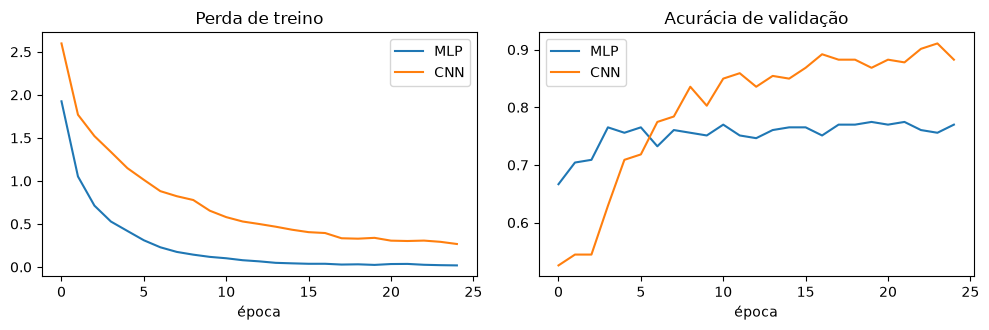

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for nome, r in resultados.items():
    ax[0].plot([x[0] for x in r['hist']], label=nome); ax[1].plot([x[1] for x in r['hist']], label=nome)
ax[0].set_title('Perda de treino'); ax[1].set_title('Acurácia de validação'); ax[0].legend(); ax[1].legend()
for a in ax: a.set_xlabel('época')
plt.tight_layout(); plt.savefig(SAIDA/'curvas.png', dpi=130); plt.show()

**Leitura:** a CNN costuma superar o MLP com **muito menos parâmetros**, porque explora a estrutura 2D e reaproveita filtros em toda a imagem (Seção 2.5). Ainda assim, ambos classificam palavras inteiras de um vocabulário fechado, sem sequência: o próximo passo é modelar a ordem das colunas.